# Wrażliwość wyników na podział: Bag of Words + regresja logistyczna na 10 ziarnach

Wszystkie eksperymenty używają jednego podziału 60/30/10 na poziomie klastrów (ziarno 42). Ten notebook sprawdza, ile
wyniki zmieniają się tylko przez losowanie klastrów, czyli jaki rozrzut metryk nie wynika z modelu.

- **Model:** baseline BoW + LR jak w `bow_lr_spam_0/1`, uczony jeden raz na każdy podział i wariant etykiet.
- **Podział:** `make_split` z ziarnami 42 i 0–8. Ziarno zmienia tylko kolejność klastrów w warstwach (source, kind).
- **Próg:** jak w pozostałych eksperymentach, FPR ważony klastrami 1% na val.
- **Wynik:** średnia i odchylenie standardowe metryk dla ID, OOD i każdego źródła oraz rozkład ROC AUC na wykresie.

In [ ]:
import sys
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from experiment_utils import (
    CORPUS_COLORS, ID_SOURCES, INK_SECONDARY, OOD_SOURCES, corpus_metrics, load_corpora, make_split, threshold_at_fpr,
)

EXPERIMENT = "bow_lr_split_seeds"
LABELS = {"spam_0": "label_spam_0", "spam_1": "label_spam_1"}
SEEDS = [42, *range(9)]
RESULTS = ROOT / "results" / EXPERIMENT
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 100, "display.float_format", "{:.4f}".format)

## Uczenie na każdym podziale

In [2]:
in_domain, out_of_domain = load_corpora()
rows = []
for seed in SEEDS:
    split = make_split(in_domain, seed)
    train, val, test = (in_domain[split == name] for name in ("train", "val", "test"))
    start = time.perf_counter()
    vectorizer = CountVectorizer()
    features_train = vectorizer.fit_transform(train.text)
    features = {name: vectorizer.transform(frame.text) for name, frame in (("val", val), ("test", test), ("ood", out_of_domain))}
    for variant, label in LABELS.items():
        model = LogisticRegression(max_iter=2000).fit(features_train, train[label])
        assert model.n_iter_[0] < model.max_iter, "Solver nie zbiegł"
        scores = {name: model.predict_proba(matrix)[:, 1] for name, matrix in features.items()}
        threshold_result = threshold_at_fpr(val[label], scores["val"], val.cluster)
        sets = {"ID": (test[label], scores["test"]), "OOD": (out_of_domain[label], scores["ood"])}
        sets |= {name: (test.loc[test.source == name, label], scores["test"][(test.source == name).to_numpy()]) for name in ID_SOURCES}
        sets |= {
            name: (out_of_domain.loc[out_of_domain.source == name, label], scores["ood"][(out_of_domain.source == name).to_numpy()])
            for name in OOD_SOURCES
        }
        metrics = corpus_metrics(sets, threshold_result["próg"])
        metrics.index.name = "zbiór"
        rows.append(metrics.reset_index().assign(wariant=variant, ziarno=seed, **threshold_result))
    print(f"ziarno {seed}: {time.perf_counter() - start:.0f} s", flush=True)

per_seed = pd.concat(rows, ignore_index=True)
per_seed.to_csv(TABLES / "metrics_per_seed.csv", index=False)

ziarno 42: 80 s


ziarno 0: 92 s


ziarno 1: 94 s


ziarno 2: 88 s


ziarno 3: 90 s


ziarno 4: 102 s


ziarno 5: 95 s


ziarno 6: 93 s


ziarno 7: 81 s


ziarno 8: 90 s


## Średnia i odchylenie standardowe

`std` to odchylenie standardowe z 10 podziałów. Różnice między modelami mniejsze niż około dwa takie odchylenia
mogą wynikać z samego podziału.

In [3]:
ORDER = ["ID", "OOD", *ID_SOURCES, *OOD_SOURCES]
SUMMARY_METRICS = ["roc_auc", "aucpr", "recall", "fpr", "f1"]
summary = per_seed.groupby(["wariant", "zbiór"])[SUMMARY_METRICS].agg(["mean", "std", "min", "max"])
summary.columns = [f"{metric}_{statistic}" for metric, statistic in summary.columns]
summary = summary.reindex(pd.MultiIndex.from_product([list(LABELS), ORDER], names=["wariant", "zbiór"])).dropna(how="all")
summary.to_csv(TABLES / "metrics_summary.csv")
display(summary[[f"{metric}_{statistic}" for metric in SUMMARY_METRICS for statistic in ("mean", "std")]])

roc_auc_mean  roc_auc_std  aucpr_mean  aucpr_std  recall_mean  recall_std  fpr_mean  fpr_std  f1_mean  f1_std
wariant zbiór                                                                                                                  
spam_0  ID              0.9740       0.0057      0.8683     0.0335       0.8169      0.0255    0.0144   0.0047   0.8315  0.0291
        OOD             0.5915       0.0847      0.8766     0.0333       0.5710      0.0732    0.4646   0.1435   0.6789  0.0560
        nazario            NaN          NaN         NaN        NaN       0.8613      0.0249       NaN      NaN   0.9253  0.0146
        nigerian           NaN          NaN         NaN        NaN       0.7108      0.0487       NaN      NaN   0.8301  0.0337
        trec05             NaN          NaN         NaN        NaN          NaN         NaN    0.0188   0.0033   0.0000  0.0000
        trec06             NaN          NaN         NaN        NaN          NaN         NaN    0.0137   0.0038   0.0000  0.0000
        trec07             NaN          NaN         NaN        NaN          NaN         NaN    0.0101   0.0088   0.0000  0.0000
        ferb            0.5463       0.1045      0.8826     0.0358       0.5678      0.0764    0.5292   0.1796   0.6783  0.0591
        kd10000         0.9535       0.0366      0.9955     0.0040       0.4455      0.1453    0.0000   0.0000   0.6033  0.1443
        nebulon         0.7769       0.0107      0.7279     0.0290       0.5739      0.0405    0.1842   0.0328   0.6454  0.0232
        zeroday         0.8010       0.0160      0.8402     0.0184       0.7109      0.0250    0.2537   0.0406   0.7202  0.0130
spam_1  ID              0.9875       0.0023      0.9827     0.0036       0.7879      0.0490    0.0099   0.0024   0.8755  0.0306
        OOD             0.7651       0.0362      0.9392     0.0105       0.5403      0.0640    0.1293   0.0702   0.6864  0.0471
        nazario            NaN          NaN         NaN        NaN       0.8204      0.0339       NaN      NaN   0.9010  0.0207
        nigerian           NaN          NaN         NaN        NaN       0.9493      0.0225       NaN      NaN   0.9738  0.0118
        trec05          0.9830       0.0053      0.9712     0.0090       0.7032      0.0837    0.0098   0.0051   0.8164  0.0573
        trec06          0.9846       0.0039      0.9347     0.0117       0.6370      0.0448    0.0092   0.0031   0.7632  0.0320
        trec07          0.9899       0.0014      0.9860     0.0041       0.8463      0.0499    0.0104   0.0017   0.9116  0.0295
        ferb            0.7453       0.0427      0.9439     0.0107       0.5322      0.0658    0.1433   0.0848   0.6805  0.0492
        kd10000         0.9996       0.0011      1.0000     0.0001       0.4309      0.1610    0.0000   0.0000   0.5873  0.1489
        nebulon         0.8028       0.0081      0.8097     0.0077       0.3551      0.0417    0.0421   0.0121   0.5054  0.0427
        zeroday         0.9563       0.0071      0.9619     0.0062       0.9038      0.0262    0.0969   0.0298   0.9018  0.0160

Próg na val: FPR ważony jest z definicji około 1%, ale zwykły FPR zależy od tego, które duże klastry hamu trafiły do val.

In [4]:
thresholds = per_seed.drop_duplicates(["wariant", "ziarno"])[["wariant", "ziarno", "próg", "fpr_ważony_val", "fpr_val", "recall_val"]]
thresholds.to_csv(TABLES / "threshold_per_seed.csv", index=False)
display(thresholds.groupby("wariant")[["próg", "fpr_ważony_val", "fpr_val", "recall_val"]].agg(["mean", "std", "min", "max"]))

próg                      fpr_ważony_val                      fpr_val                      recall_val                     
          mean    std    min    max           mean    std    min    max    mean    std    min    max       mean    std    min    max
wariant                                                                                                                             
spam_0  0.3819 0.0722 0.2760 0.5300         0.0100 0.0000 0.0100 0.0100  0.0198 0.0025 0.0161 0.0246     0.8527 0.0229 0.8095 0.8808
spam_1  0.9719 0.0170 0.9400 0.9868         0.0100 0.0000 0.0099 0.0100  0.0153 0.0043 0.0104 0.0215     0.7877 0.0267 0.7531 0.8200

## Rozkład ROC AUC między podziałami

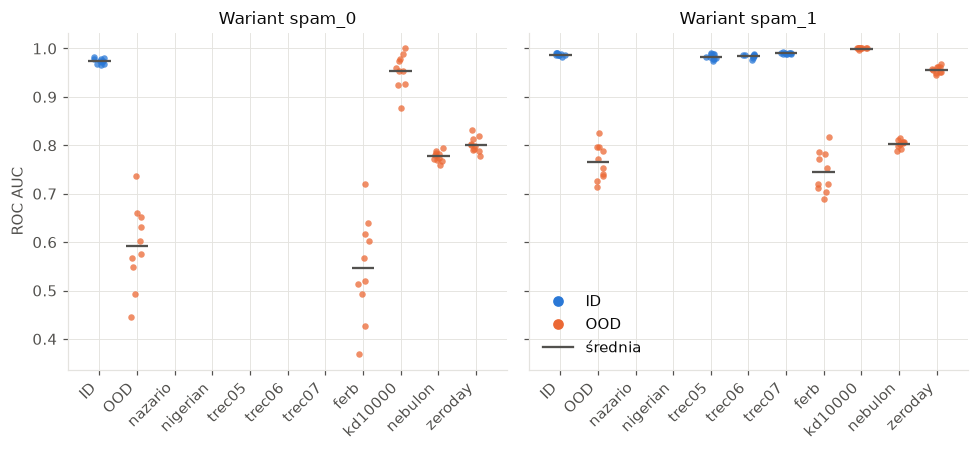

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharey=True)
positions = np.arange(len(ORDER))
rng = np.random.default_rng(0)
for axis, variant in zip(axes, LABELS):
    data = per_seed[per_seed.wariant == variant].set_index("zbiór")
    for position, name in zip(positions, ORDER):
        values = data.loc[[name], "roc_auc"].dropna().to_numpy()
        if not len(values):
            continue
        color = CORPUS_COLORS["OOD"] if name == "OOD" or name in OOD_SOURCES else CORPUS_COLORS["ID"]
        axis.scatter(np.full(len(values), position) + rng.uniform(-0.15, 0.15, len(values)), values, s=18, color=color, alpha=0.75, linewidths=0)
        axis.hlines(values.mean(), position - 0.3, position + 0.3, color=INK_SECONDARY, linewidth=1.5)
    axis.set_xticks(positions, ORDER, rotation=45, ha="right")
    axis.set_title(f"Wariant {variant}")
axes[0].set_ylabel("ROC AUC")
handles = [plt.Line2D([], [], marker="o", linestyle="", color=CORPUS_COLORS[name], label=name) for name in ("ID", "OOD")]
handles.append(plt.Line2D([], [], color=INK_SECONDARY, linewidth=1.5, label="średnia"))
axes[1].legend(handles=handles, loc="lower left")
figure.tight_layout()
figure.savefig(FIGURES / "roc_auc_per_seed.pdf")
plt.show()